# hiPSC-CM Post-Flight Heatmap — Manuscript-Cited Genes

Heatmap of the genes explicitly discussed by symbol in the manuscript
*"Comparative Pathway Analysis Reveals Persistent Metal-Homeostasis and
Post-Flight Metabolic Remodeling in Spaceflown Human iPSC-Derived
Cardiomyocytes."*

Genes are grouped by the biological themes used in the Results section:

1. Metal homeostasis / Zn signaling
2. Lipid, cholesterol & lipoprotein regulation
3. Cardiac contractile & structural genes
4. Ion channel genes
5. Inflammatory / cytokine-responsive & stress genes
6. ECM, vascular & metabolic genes
7. Cross-comparison persistent gene (HMSD)

Values (Expression Log Ratio) are read directly from the paper's own
supplementary DEG tables (`IPA_Supplementary.xlsx`, sheets `DEGs_FG`,
`DEGs_PFF`, `DEGs_PFG`) for all three comparisons:

- **Flight vs Ground**
- **Post Flight vs Flight**
- **Post Flight vs Ground**

Blank cells mean the gene was not part of the filtered DEG list for that
comparison (|log2FC| > 2, nominal *p* < 0.05, adjusted *p* < 0.05) — i.e.
not reported, not zero.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl

## 1. Load source data from the paper's supplementary Excel file

In [5]:
SRC = "/content/IPA_Supplementary.xlsx"
wb = openpyxl.load_workbook(SRC, data_only=True)

def sheet_to_dict(sheet_name):
    ws = wb[sheet_name]
    out = {}
    for row in ws.iter_rows(min_row=2, values_only=True):
        symbol, log_ratio = row[0], row[3]
        if symbol is not None and log_ratio is not None:
            out[symbol] = log_ratio
    return out

fg_vals  = sheet_to_dict("DEGs_FG")    # Flight vs Ground
pff_vals = sheet_to_dict("DEGs_PFF")   # Post Flight vs Flight
pfg_vals = sheet_to_dict("DEGs_PFG")   # Post Flight vs Ground

print(f"Loaded {len(fg_vals)} FG genes, {len(pff_vals)} PFF genes, {len(pfg_vals)} PFG genes")

Loaded 103 FG genes, 223 PFF genes, 463 PFG genes


## 2. Gene set — only genes explicitly named by symbol in the manuscript text

Grouped into the biological themes used in the Results section. Category names use a manual line break so the horizontal (non-rotated) labels stay compact next to the heatmap.

In [6]:
categories = {
    "Metal homeostasis /\nZn signaling": [
        "MT1E", "MT1F", "MT1G", "MT1H", "MT1L", "MT1M", "SLC39A2",
    ],
    "Lipid, cholesterol &\nlipoprotein regulation": [
        "APOA1", "APOA2", "APOA4", "APOC1", "APOC2", "ARG2", "RBP4",
        "ANGPTL3", "LIPC", "ALB", "AHSG", "TF", "NR0B2",
    ],
    "Cardiac contractile &\nstructural genes": [
        "ACTN2", "ACTN3", "CAV3", "FGF12", "GJA4", "HRC", "KCNH6", "NPPA",
        "GLP1R", "IRX4", "MYL2", "PTH1R", "RRAD", "S100A1", "TRIM54",
        "TRIM55", "TRIM63", "HAND1", "TCAP", "MYOT", "TNNI1", "MYH7B",
        "LMOD2", "LMOD3", "MYBPH",
    ],
    "Ion channel\ngenes": [
        "KCNK4", "KCNJ15", "CACNA1E", "KCNA2",
    ],
    "Inflammatory / cytokine-\nresponsive & stress genes": [
        "CRP", "EGR1", "EGR3", "EGR4", "IL1RN", "IL1RL2", "IL24", "MMP19",
        "NCF2", "PDK4", "SAA1", "CCL26", "IL13RA2", "SERPINB2", "ALOX15",
        "HSPA6", "HSPB3", "GDF15", "C5AR2", "APCS",
    ],
    "ECM, vascular &\nmetabolic genes": [
        "MMP3", "CILP", "VEGFD", "PROK1", "SH2D2A", "CKMT2", "COX6A2",
        "NMRK2", "CHCHD10", "CXCR6",
    ],
    "Cross-comparison\npersistent gene": [
        "HMSD",
    ],
}

columns = ["Flight vs Ground", "Post Flight vs Flight", "Post Flight vs Ground"]

## 3. Build the data table (sorted within each theme by Post Flight vs Ground magnitude)

In [7]:
rows = []
gene_order = []
group_sizes = []
for cat, genes in categories.items():
    group_sizes.append(len(genes))
    genes_sorted = sorted(genes, key=lambda g: pfg_vals.get(g, 0), reverse=True)
    for g in genes_sorted:
        gene_order.append(g)
        rows.append([fg_vals.get(g, np.nan), pff_vals.get(g, np.nan), pfg_vals.get(g, np.nan)])

df = pd.DataFrame(rows, index=gene_order, columns=columns)
print(f"Total genes plotted: {df.shape[0]} (all explicitly named in the manuscript text)")
df.head(10)

Total genes plotted: 80 (all explicitly named in the manuscript text)


,Flight vs Ground,Post Flight vs Flight,Post Flight vs Ground
MT1H,6.423,NaN,7.985
MT1M,6.699,NaN,7.609
MT1G,4.397,NaN,5.484
SLC39A2,3.615,NaN,3.766
MT1F,2.305,NaN,3.173
MT1E,2.432,NaN,3.102
MT1L,2.584,NaN,2.861
TF,NaN,NaN,4.022
APOC2,NaN,NaN,3.975
APOA4,NaN,NaN,3.853


## 4. Plot — compact, bold, publication-ready heatmap

- Category names are horizontal (not rotated)
- Overall plot height is reduced (compact row spacing)
- Gene names on the y-axis use a large, bold font
- In-cell values are bold, with automatic white/black contrast
- Saved at 300 DPI (PNG) plus a vector PDF

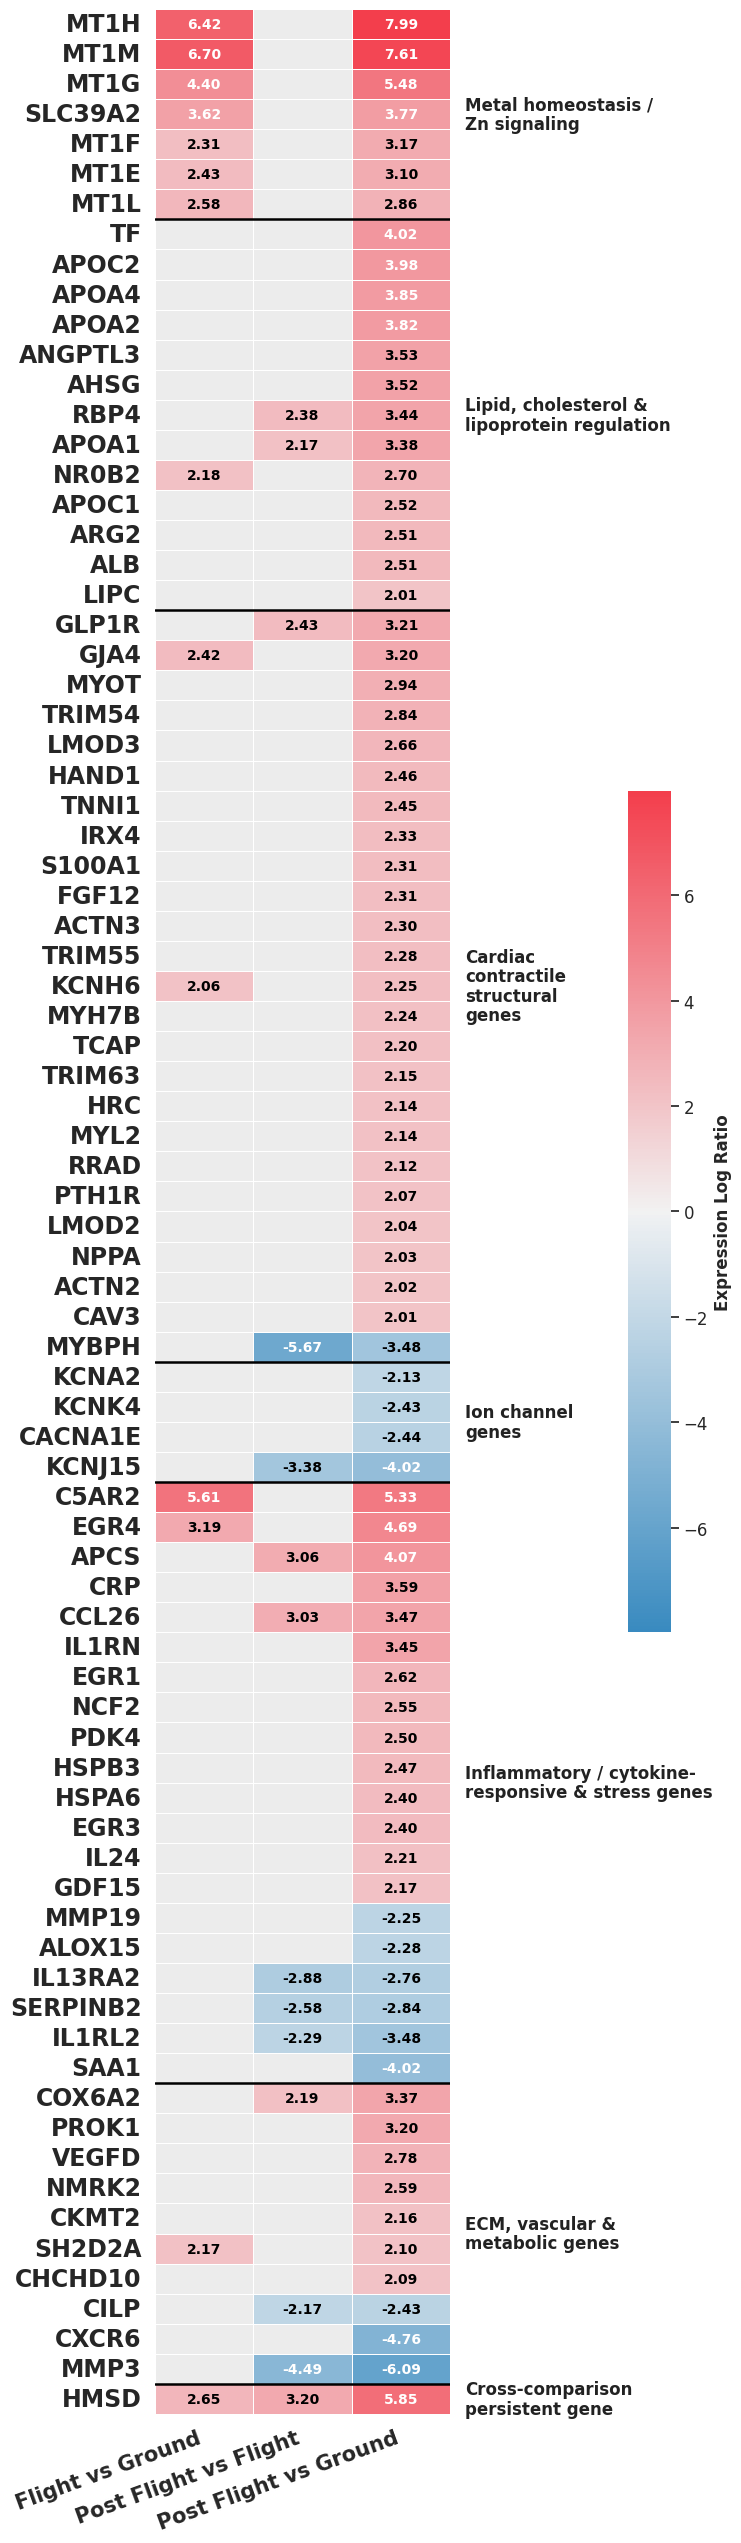

In [23]:
sns.set(style="white")

n_genes = len(df)
fig_height = 0.30 * n_genes + 1.6   # compact row height

fig, ax = plt.subplots(figsize=(12, fig_height))

cmap = sns.diverging_palette(240, 10, s=85, l=55, as_cmap=True)  # blue (down) -> red (up)
vmax = np.nanmax(np.abs(df.values))

hm = sns.heatmap(
    df,
    cmap=cmap,
    center=0,
    vmin=-vmax,
    vmax=vmax,
    annot=False,          # bold annotations added manually below for full control
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"label": "Expression Log Ratio", "shrink": 0.35, "pad": 0.32},
    mask=df.isna(),
    ax=ax,
)

hm.set_facecolor("#ececec")  # visible background for NaN / not-reported cells

# ---- Bold in-cell value annotations ----
for i, gene in enumerate(df.index):
    for j, col in enumerate(df.columns):
        val = df.iloc[i, j]
        if pd.notna(val):
            norm = val / vmax if vmax else 0
            text_color = "white" if abs(norm) > 0.45 else "black"
            ax.text(
                j + 0.5, i + 0.5, f"{val:.2f}",
                ha="center", va="center",
                fontsize=10, fontweight="bold",
                color=text_color,
            )

# ---- Larger, bold gene-name labels on the y-axis ----
ax.set_yticklabels(df.index, fontsize=17, fontweight="bold", rotation=0)
ax.set_xticklabels(df.columns, fontsize=15, fontweight="bold", rotation=20, ha="right")

# ---- Divider lines between biological-theme blocks ----
cum = 0
for size in group_sizes[:-1]:
    cum += size
    ax.axhline(cum, color="black", linewidth=1.8)

# ---- Category labels to the right of each block ----
cum = 0

for cat, size in zip(categories.keys(), group_sizes):

    y_center = cum + size / 2
    cat_clean = " ".join(str(cat).split())

    if "Cardiac" in cat_clean:
        display_cat = "Cardiac\ncontractile\nstructural\ngenes"
    else:
        display_cat = cat

    ax.text(
        3.15, y_center, display_cat,
        ha="left",
        va="center",
        fontsize=12,
        fontweight="bold",
        color="#222222",
        rotation=0,
        transform=ax.transData,
        linespacing=1.1,
    )

    cum += size

ax.set_xlabel("")
ax.set_ylabel("")

cbar = hm.collections[0].colorbar
cbar.set_label("Expression Log Ratio", fontsize=12, fontweight="bold")
cbar.ax.tick_params(labelsize=12)

plt.tight_layout()
plt.subplots_adjust(right=0.60)
plt.show()

## 5. Save outputs (300 DPI PNG, vector PDF, and the underlying data table as CSV)

In [10]:
out_png = "/content"
out_pdf = "/content"
fig.savefig(out_png, dpi=300, bbox_inches="tight")
fig.savefig(out_pdf, bbox_inches="tight")
print(f"Saved: {out_png}")
print(f"Saved: {out_pdf}")

df.to_csv("/mnt/user-data/outputs/hipsc_cm_paper_genes_table.csv")
print("Saved: hipsc_cm_paper_genes_table.csv")

Saved: /content
Saved: /content


OSError: Cannot save file into a non-existent directory: '/mnt/user-data/outputs'